# A rod that warms up: transient heat conduction with Python

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 05 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/05_Transient_Heat_Conduction_in_a_Rod.ipynb)

**Audience:** first-year engineering students; no previous heat-transfer course needed.  
**Run time:** the cells are intentionally small and can be run from top to bottom with NumPy and Matplotlib.

Imagine a thin, uniform rod whose left end is suddenly held against a warm plate. Initially, most of the rod is cool. What temperatures will we see a few seconds later? When will the rod stop changing? We will answer these questions by repeatedly applying a simple rule: **a location warms when its neighbors collectively send it more heat than it sends away.**

By the end, you can explain what temperature, thermal conductivity, heat capacity, and diffusivity do; build an explicit numerical model; check its units, boundary conditions, and stability; verify it against a known solution; and recognize when an apparently dramatic plot is a numerical mistake. A clearly marked optional section connects the model to a calculus equation and an exact solution.

**How to study:** Predict what each cell will do, run it, and compare the output with your prediction. Temperatures are in °C; differences of temperature have the same numerical size in °C and K. The numerical material properties below are illustrative rather than a claim about a named material.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 2, Collections and data |
| **Time** | about 45 min (about 90 min with exercises) |
| **Before this** | Notebooks 01–04. No NumPy is needed beforehand: Section 0 introduces arrays. |
| **Essential** | Section 0, then Sections 1–9, skipping the subsections marked optional. |
| **Optional on a first reading** | The optional subsections of Section 5 (calculus connection, numerical studies A and B) and of Section 8 (direction of heat flow). |
| **Next** | 06, Drawing heart curves (more practice with arrays and plots). |

**You have understood this notebook if you can, without looking back:**

1. Explain the update rule for one interior node, and what the number r = αΔt/Δx² controls.
2. Choose a stable time step, and recognise from a plot when a simulation has become unstable.
3. Explain why updating the temperature list in place gives wrong results, and fix it by working from a copy.
4. Check a result against physics: a straight-line steady profile with fixed ends, and constant total heat with insulated ends.
5. Use a loop with a stopping condition to find when the middle of the rod reaches 55 °C.

**Not expected of you:** Deriving the heat equation, and the sine-solution calculus.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

<!-- pfe-numpy-bridge -->
## 0. Before we start: from lists to NumPy arrays

This is the first notebook in the collection that uses **NumPy**, Python's standard library for arrays of numbers. In notebooks 01–04, a list of values was processed with a `for` loop, one element at a time. A NumPy **array** stores numbers of one type together and does arithmetic on all of them at once. Five ideas are enough for this notebook:

| Idea | Example | Result |
|---|---|---|
| make an array from a list | `np.array([1.0, 2.0])` | an array of two numbers |
| evenly spaced values, ends included | `np.linspace(0, 0.2, 5)` | 0, 0.05, 0.10, 0.15, 0.20 |
| arithmetic on every element | `T + 273.15` | every temperature in kelvin |
| slices pick out neighbours | `T[1:-1]`, `T[:-2]`, `T[2:]` | interior nodes, their left and their right neighbours |
| an independent copy | `T.copy()` | a new array; changing it leaves `T` unchanged |

The cell below makes one update step for a five-node rod twice: once with arrays and slices, once with a list and a loop. The two must agree.

In [1]:
# pfe-numpy-bridge: NumPy is imported under its usual short name, np.
import numpy as np
# A plain list of five temperatures in °C: a hot left end, the rest at 20 °C.
temps_list = [100.0, 20.0, 20.0, 20.0, 20.0]
# The same numbers as a NumPy array.
temps = np.array(temps_list)
# Arithmetic acts on every element at once: all temperatures in kelvin.
print("in kelvin:", temps + 273.15)
# With lists, + joins two lists instead of adding numbers.
print("list + list joins them:", temps_list + [0.0])
# Five equally spaced positions from 0 to 0.2 m, both ends included.
print("positions:", np.linspace(0.0, 0.2, 5))
# Slices: the interior nodes, their left neighbours and their right neighbours.
print("T[1:-1] =", temps[1:-1], " T[:-2] =", temps[:-2], " T[2:] =", temps[2:])
# The update number for this small example.
r = 0.25
# Array version: work on a copy, so the old values stay available.
new_array = temps.copy()
# One line updates every interior node from its two old neighbours.
new_array[1:-1] = temps[1:-1] + r * (temps[:-2] - 2 * temps[1:-1] + temps[2:])
# List version: also start from a copy.
new_list = temps_list.copy()
# Visit the interior nodes one at a time.
for i in range(1, len(temps_list) - 1):
    # The same update for node i, from old values only.
    new_list[i] = temps_list[i] + r * (temps_list[i - 1] - 2 * temps_list[i] + temps_list[i + 1])
# Show both results.
print("array step:", new_array, " list step:", new_list)
# The two versions must agree to round-off.
assert np.allclose(new_array, new_list)

in kelvin: [373.15 293.15 293.15 293.15 293.15]
list + list joins them: [100.0, 20.0, 20.0, 20.0, 20.0, 0.0]
positions: [0.   0.05 0.1  0.15 0.2 ]
T[1:-1] = [20. 20. 20.]  T[:-2] = [100.  20.  20.]  T[2:] = [20. 20. 20.]
array step: [100.  40.  20.  20.  20.]  list step: [100.0, 40.0, 20.0, 20.0, 20.0]


<!-- pfe-numpy-bridge -->
The array version is shorter and, for a long rod, much faster, because the loop runs inside NumPy's compiled code. The rest of this notebook uses arrays throughout. If a line with slices is unclear, write out the loop version for a five-node rod, as above, and compare the two.

## 1. What is moving, and what is stored?

Temperature tells us how warm each small piece of rod is. Heat is energy transferred because neighboring pieces have different temperatures. If a hot piece touches a cooler piece, energy flows from hot to cool. A larger **thermal conductivity** $k$ makes the transfer stronger; a larger density $\rho$ or specific heat capacity $c_p$ means more energy is needed to change the same piece's temperature. Their combination is **thermal diffusivity**,

$$\alpha=\frac{k}{\rho c_p}, \qquad [\alpha]=\mathrm{m^2/s}.$$

For a rod with constant cross-sectional area and no sideways heat loss, the cross-sectional area cancels from this temperature model. We neglect radiation, convection along the surface, internal heaters, and changes in properties with temperature. Those effects can be added later.

**Reading the figures:** every plot uses the same restrained colors, type sizes, and axis conventions. Markers show values stored by the program; smooth curves show a formula or a guide where stated. Figure captions say what is being compared. The notebook includes scalable SVG output as well as a high-resolution PNG fallback. If you need a standalone vector figure after running a plot cell, place `fig.savefig("figure_name.pdf", bbox_inches="tight")` immediately before `plt.show()` in that cell.

In [2]:
# Import NumPy to store temperatures in arrays and to compute with all grid points.
import numpy as np
# Import Matplotlib's plotting interface for profiles and diagnostic figures.
import matplotlib.pyplot as plt
# Use a reliable, readable sans-serif font for labels and mathematical notation.
plt.rcParams["font.family"] = "DejaVu Sans"
# Set a consistent text size for normal axes and captions inside the figures.
plt.rcParams["font.size"] = 10
# Make axis labels readable when the figure is reduced for a report page.
plt.rcParams["axes.labelsize"] = 10
# Keep plot titles modest so that data remain the main focus.
plt.rcParams["axes.titlesize"] = 11
# Use slightly smaller tick labels and legend text than the axis labels.
plt.rcParams["xtick.labelsize"] = 9
# Apply the same compact size to the vertical tick labels.
plt.rcParams["ytick.labelsize"] = 9
# Make legend entries readable without covering too much of a curve.
plt.rcParams["legend.fontsize"] = 9
# Hide the top border, which does not encode additional information here.
plt.rcParams["axes.spines.top"] = False
# Hide the right border for ordinary plots; all panels have their own y axis.
plt.rcParams["axes.spines.right"] = False
# Increase display resolution for notebook views that use a raster renderer.
plt.rcParams["figure.dpi"] = 160
# Keep text as editable text when a vector SVG figure is exported.
plt.rcParams["svg.fonttype"] = "none"
# Use dark blue, orange, green, vermilion, purple, and gray for clear contrasts.
plot_colors = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#4D4D4D"]

The numbers below make the arithmetic easy: conductivity $270\ \mathrm{W/(m\,K)}$, density $3000\ \mathrm{kg/m^3}$, and heat capacity $900\ \mathrm{J/(kg\,K)}$. A watt is a joule per second. Consequently, $k/(\rho c_p)$ has units $(\mathrm{J/(s\,m\,K)})/(\mathrm{J/(m^3\,K)})=\mathrm{m^2/s}$.

In [3]:
# Set an illustrative thermal conductivity in watts per meter per kelvin.
k = 270.0
# Set an illustrative density in kilograms per cubic meter.
rho = 3000.0
# Set an illustrative specific heat capacity in joules per kilogram per kelvin.
cp = 900.0
# Divide conductivity by volumetric heat capacity to obtain thermal diffusivity.
alpha = k / (rho * cp)
# Display the result with units so that the number has a physical interpretation.
print(f"Thermal diffusivity = {alpha:.2e} m²/s")
# Check this deliberately chosen example against the value used later in estimates.
assert np.isclose(alpha, 1.0e-4)

Thermal diffusivity = 1.00e-04 m²/s


## 2. Replace the continuous rod by a short list

Let $x=0$ be the left end and $x=L$ the right end. We store temperatures at 21 equally spaced **nodes**, including both ends. For $L=0.20\ \mathrm{m}$, the spacing is $\Delta x=L/(N-1)=0.01\ \mathrm{m}$. The Python array index $i$ labels the physical position $x_i=i\Delta x$. The two end nodes have prescribed temperatures and are never updated by the interior rule.

In [4]:
# Specify a rod that is 20 centimeters long, measured in meters.
L = 0.20
# Include both boundary positions among the 21 temperature nodes.
N = 21
# Make the physical coordinate of every node, including 0 and L.
x = np.linspace(0.0, L, N)
# Compute the distance between adjacent nodes from the length and node count.
dx = L / (N - 1)
# Print three representative locations to connect array indices to distances.
print(f"dx = {dx:.3f} m; x[0] = {x[0]:.2f}, x[10] = {x[10]:.2f}, x[-1] = {x[-1]:.2f} m")
# Confirm that NumPy created exactly the requested number of nodes.
assert len(x) == N

dx = 0.010 m; x[0] = 0.00, x[10] = 0.10, x[-1] = 0.20 m


### Our first experiment: fixed temperatures at both ends

The rod begins at 20 °C. At time zero, a temperature-controlled plate holds the left end at 100 °C; another device holds the right end at 20 °C. We treat these temperatures as fixed for all later times. The sudden jump at the first node describes switching on the left plate at the start. It is an **initial condition**, followed by two **boundary conditions**.

In [5]:
# Store the temperature maintained by the warm left-hand plate.
left_temperature = 100.0
# Store the temperature maintained at the cool right-hand end.
right_temperature = 20.0
# Start all 21 nodes at the original uniform temperature of 20 °C.
T_initial = np.full(N, 20.0)
# Replace the left boundary node because the heater is switched on at time zero.
T_initial[0] = left_temperature
# Explicitly set the right boundary to document its prescribed temperature.
T_initial[-1] = right_temperature
# Print the array to reveal the meaning of the first and last entries.
print("Initial temperatures (°C):", T_initial)

Initial temperatures (°C): [100.  20.  20.  20.  20.  20.  20.  20.  20.  20.  20.  20.  20.  20.
  20.  20.  20.  20.  20.  20.  20.]


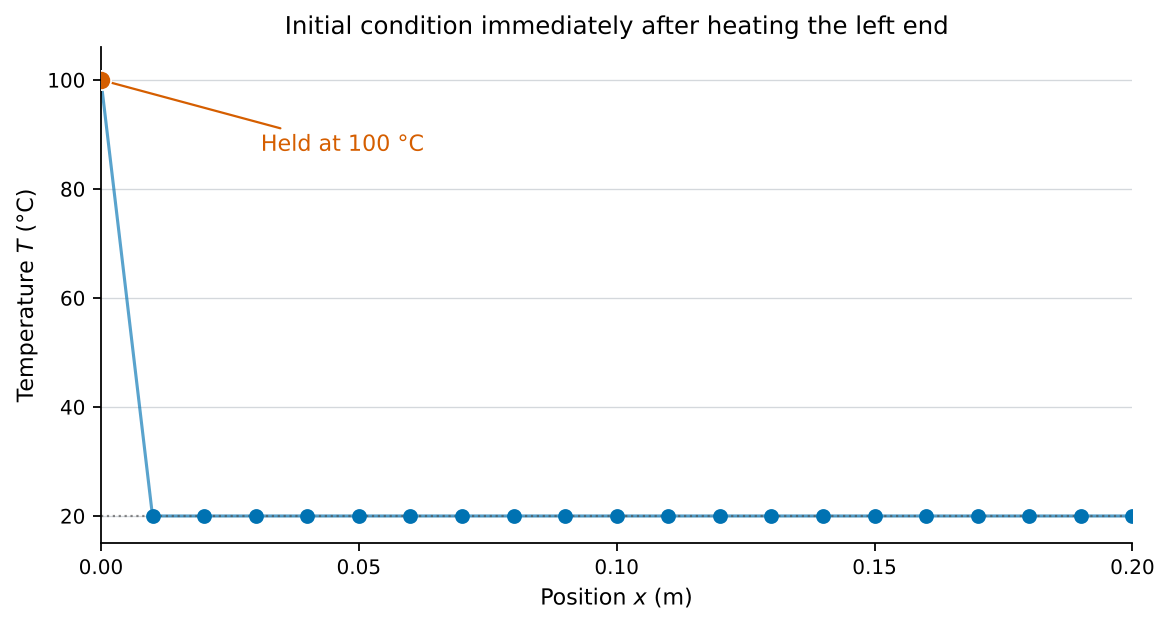

In [6]:
# Make an appropriately proportioned single-panel figure with room for labels.
fig, ax = plt.subplots(figsize=(7.2, 3.8), layout="constrained")
# Draw a thin guide joining the nodal values so their spatial ordering is visible.
ax.plot(x, T_initial, color=plot_colors[0], linewidth=1.4, alpha=0.65)
# Draw all stored temperatures as explicit markers, including both boundaries.
ax.scatter(x, T_initial, color=plot_colors[0], s=32, zorder=3)
# Highlight the boundary that has just been clamped to the warm plate.
ax.scatter([0.0], [left_temperature], facecolor=plot_colors[3], edgecolor="white", linewidth=0.8, s=75, zorder=4)
# Add the originally uniform 20 °C level as a light visual reference.
ax.axhline(20.0, color=plot_colors[5], linestyle=":", linewidth=1.0, alpha=0.65)
# Identify the sudden imposed boundary temperature without relying on a legend.
ax.annotate("Held at 100 °C", xy=(0.0, 100.0), xytext=(0.031, 87.0), arrowprops={"arrowstyle": "-", "color": plot_colors[3]}, color=plot_colors[3])
# Label physical position using the same SI unit used in the numerical grid.
ax.set_xlabel("Position $x$ (m)")
# Label the vertical temperature axis with its Celsius unit.
ax.set_ylabel("Temperature $T$ (°C)")
# State the physical instant represented by these discrete node values.
ax.set_title("Initial condition immediately after heating the left end")
# Show the exact physical extent of the 20 cm rod.
ax.set_xlim(0.0, L)
# Show a little space above and below the values and annotation.
ax.set_ylim(15.0, 106.0)
# Use a small set of meaningful, evenly spaced position tick marks.
ax.set_xticks(np.linspace(0.0, L, 5))
# Add subtle horizontal guides without overwhelming the temperature markers.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the figure in the notebook.
plt.show()

**Figure 1.** The 21 dots are stored nodal temperatures at the initial instant. The connecting line is a visual guide between discrete values, not a resolved account of what occurs between the hot end and its first interior node.

## 3. The rule for one small time step

Here is the connection from energy accounting to the computer rule, without requiring calculus. Imagine an interior piece of length $\Delta x$ and cross-sectional area $A$. Its approximate heat-storage capacity is $\rho c_p A\Delta x$ joules per kelvin. During a short interval $\Delta t$, the heat arriving from its left neighbor is approximately $kA\Delta t(T_{i-1}-T_i)/\Delta x$ joules; the right neighbor contributes $kA\Delta t(T_{i+1}-T_i)/\Delta x$. Divide their sum by the piece's heat-storage capacity to convert transferred energy into a temperature change. The area $A$ cancels, leaving $\alpha\Delta t/(\Delta x)^2$ times the sum of the two temperature differences. This is the finite-difference model for an interior location; the physical behavior at the ends must still be specified separately.

Focus on an interior node $i$. Its left neighbor is $i-1$ and its right neighbor is $i+1$. The net exchange is proportional to

$$T_{i-1}^{\mathrm{old}}-2T_i^{\mathrm{old}}+T_{i+1}^{\mathrm{old}}=(T_{i-1}^{\mathrm{old}}-T_i^{\mathrm{old}})+(T_{i+1}^{\mathrm{old}}-T_i^{\mathrm{old}}).$$

The superscript “old” matters: all changes during one step must use the **same previous snapshot**. We scale the exchange by the dimensionless number

$$r=\frac{\alpha\,\Delta t}{(\Delta x)^2}.$$

The resulting **explicit update** is $T_i^{\mathrm{new}}=T_i^{\mathrm{old}}+r(T_{i-1}^{\mathrm{old}}-2T_i^{\mathrm{old}}+T_{i+1}^{\mathrm{old}})$. This equation predicts the *next temperature*, rather than requiring us to solve simultaneously for unknown future neighbors.

In [7]:
# Choose the first interior node, directly next to the warm left boundary.
sample_i = 1
# Read the initial left-neighbor temperature from the stored array.
sample_left = T_initial[sample_i - 1]
# Read this node's initial temperature from the same old snapshot.
sample_center = T_initial[sample_i]
# Read the initial right-neighbor temperature from that snapshot.
sample_right = T_initial[sample_i + 1]
# Add the two neighbor differences to obtain the net driving temperature.
sample_balance = sample_left - 2 * sample_center + sample_right
# Show why the first interior node initially warms while most nodes stay unchanged.
print(f"At i=1: ({sample_left:.0f} - {sample_center:.0f}) + ({sample_right:.0f} - {sample_center:.0f}) = {sample_balance:.0f} °C")

At i=1: (100 - 20) + (20 - 20) = 80 °C


### Choosing a safe time step

Rearrange the update as

$$T_i^{\mathrm{new}}=rT_{i-1}^{\mathrm{old}}+(1-2r)T_i^{\mathrm{old}}+rT_{i+1}^{\mathrm{old}}.$$

If $0\le r\le 1/2$, these three nonnegative weights add to one: the new value is an average of the old values. That gives an intuitive stability check for this particular one-dimensional explicit scheme. It also explains why halving $\Delta x$ requires a time step about four times smaller when $r$ is kept constant. We choose $\Delta t=0.2\ \mathrm{s}$, giving $r=0.2$.

In [8]:
# Advance the model by one fifth of a second in each simulation step.
dt = 0.20
# Compute the dimensionless amount of neighbor exchange in one time step.
r = alpha * dt / dx**2
# Compute the largest allowed step for the simple nonnegative-weight criterion.
dt_limit = dx**2 / (2.0 * alpha)
# Display both the chosen ratio and the limit in physical seconds.
print(f"r = {r:.3f}; chosen Δt = {dt:.2f} s; stability limit = {dt_limit:.2f} s")
# Catch an accidental change to a time step beyond the explicit stability limit.
assert 0.0 < r <= 0.5

r = 0.200; chosen Δt = 0.20 s; stability limit = 0.50 s


This function makes **one** update. It copies the old array before writing to the new array; every interior calculation therefore reads the same old temperatures. Its `ratio` input is $r$. The function itself can also be used in a deliberately unstable demonstration later; the multi-step simulation below will reject an unsafe ratio.

In [9]:
# Define a single explicit step for a grid whose endpoint temperatures are fixed.
def fixed_step(old, ratio, left, right):
    # Refuse invalid shapes, since two boundary nodes and an interior node are needed.
    if len(old) < 3:
        # Explain the grid requirement in a useful exception message.
        raise ValueError("At least three nodal temperatures are required.")
    # Copy old values so writing an updated node cannot change its neighbor's input.
    new = old.copy()
    # Visit only interior nodes; the two endpoint temperatures are prescribed separately.
    for i in range(1, len(old) - 1):
        # Add scaled exchanges from both neighboring nodes in the old snapshot.
        new[i] = old[i] + ratio * (old[i - 1] - 2.0 * old[i] + old[i + 1])
    # Restore the temperature imposed by the left-hand plate.
    new[0] = left
    # Restore the temperature imposed at the right-hand end.
    new[-1] = right
    # Hand the complete new snapshot back to the caller.
    return new

In [10]:
# Calculate the first complete time step from the original temperature profile.
T_one = fixed_step(T_initial, r, left_temperature, right_temperature)
# Independently use the handwritten balance of node 1 to predict its new value.
manual_node_one = sample_center + r * sample_balance
# Print both numbers so the connection between the formula and function is visible.
print(f"Hand calculation for node 1: {manual_node_one:.1f} °C; Python: {T_one[1]:.1f} °C")
# Verify the function agrees with the independent one-node arithmetic.
assert np.isclose(T_one[1], manual_node_one)
# Verify that making a new array did not silently modify the initial condition.
assert T_initial[1] == 20.0

Hand calculation for node 1: 36.0 °C; Python: 36.0 °C


We can now repeat the same rule ten times. After each iteration, `current` becomes the snapshot for the next iteration. Ten steps correspond to $10\times0.2=2\ \mathrm{s}$. The fixed ends remain attached to the two temperature-controlled devices.

In [11]:
# Make a fresh copy because the initial profile should remain available for comparisons.
current = T_initial.copy()
# Repeat the one-step function ten times to reach two seconds.
for step_number in range(10):
    # Update from the complete old profile to the complete new profile.
    current = fixed_step(current, r, left_temperature, right_temperature)
# Report temperatures at a few locations without printing an unwieldy history.
print(f"At t=2 s: left={current[0]:.1f}, x=0.01 m={current[1]:.1f}, middle={current[N//2]:.1f}, right={current[-1]:.1f} °C")
# Confirm that both imposed boundary values still hold after repeated steps.
assert np.isclose(current[0], left_temperature) and np.isclose(current[-1], right_temperature)

At t=2 s: left=100.0, x=0.01 m=70.1, middle=20.0, right=20.0 °C


## 4. Simulate and store snapshots

The next function collects only the time points we request. Its `steps` argument counts updates, so step 0 is the starting condition and step $n$ represents time $n\Delta t$. It guards the safe range of $r$ and returns a dictionary such as `{100: temperature_array_at_step_100}`. A snapshot is copied so that later updates cannot change an earlier result.

In [12]:
# Define a reusable driver for fixed-end rod experiments.
def simulate_fixed(start, diffusivity, spacing, time_step, steps, left, right, keep):
    # Convert the material and grid settings to the update ratio for this run.
    ratio = diffusivity * time_step / spacing**2
    # Reject negative or unsafe time steps before the requested simulation begins.
    if not (0.0 < ratio <= 0.5):
        # Give the student the physical reason for the rejected combination.
        raise ValueError("Explicit fixed-end simulation needs 0 < alpha*dt/dx² <= 0.5.")
    # Check that the requested step indices are valid for this finite run.
    if any(index < 0 or index > steps for index in keep):
        # Explain why a snapshot cannot be taken outside the simulated range.
        raise ValueError("Every requested snapshot must be between step 0 and steps.")
    # Use a set so checking whether a step was requested is quick.
    requested = set(keep)
    # Preserve the caller's input array by starting from a copy.
    current = start.copy()
    # Save a separate copy of step zero only when it was requested.
    snapshots = {0: current.copy()} if 0 in requested else {}
    # Advance sequentially through the requested number of updates.
    for index in range(1, steps + 1):
        # Reuse the one-step function, which reads the old snapshot consistently.
        current = fixed_step(current, ratio, left, right)
        # Test whether this particular step should be retained for inspection.
        if index in requested:
            # Store a copy so subsequent steps cannot alter this earlier profile.
            snapshots[index] = current.copy()
    # Return all requested temperature arrays under their step numbers.
    return snapshots

We run for 400 seconds and save six profiles. The whole history contains 2000 time steps, but we display only the times that help tell the story. Predict which part of the rod responds first and what the final shape should look like.

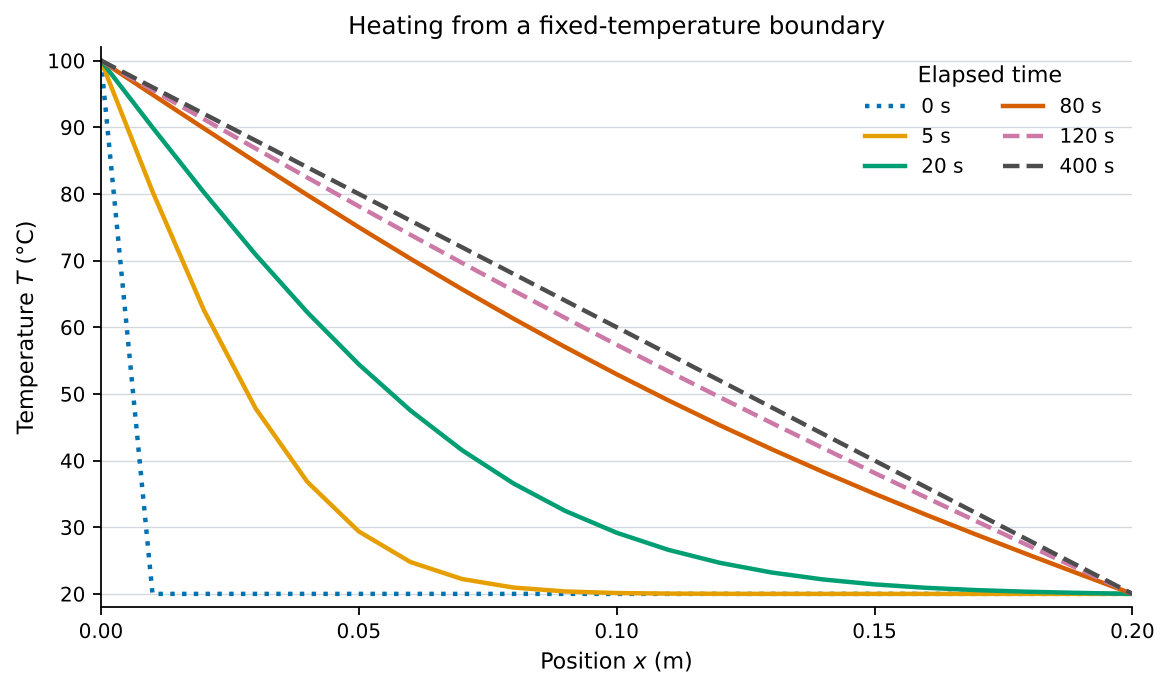

In [13]:
# Select step indices corresponding to 0, 5, 20, 80, 120, and 400 seconds.
fixed_times_steps = [0, 25, 100, 400, 600, 2000]
# Run the temperature model once and retain these six independent snapshots.
fixed_snapshots = simulate_fixed(T_initial, alpha, dx, dt, 2000, left_temperature, right_temperature, fixed_times_steps)
# Create a figure with enough width to resolve the early and late profiles.
fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
# Distinguish nearly overlapping late profiles by both color and line pattern.
line_patterns = [":", "-", "-", "-", "--", "--"]
# Draw a separate temperature profile for every selected physical time.
for position, index in enumerate(fixed_times_steps):
    # Identify the snapshot by its physical time rather than its internal index.
    label = f"{index * dt:g} s"
    # Draw each case with a consistent high-contrast color and explicit pattern.
    ax.plot(x, fixed_snapshots[index], color=plot_colors[position], linestyle=line_patterns[position], linewidth=2.0, label=label)
# Label the SI position coordinate used throughout the notebook.
ax.set_xlabel("Position $x$ (m)")
# Label the modeled temperature and its unit.
ax.set_ylabel("Temperature $T$ (°C)")
# State the boundary condition and the time development shown.
ax.set_title("Heating from a fixed-temperature boundary")
# Keep the plotted region aligned exactly with the rod endpoints.
ax.set_xlim(0.0, L)
# Make the same physical temperature range visible as in Figure 1.
ax.set_ylim(18.0, 102.0)
# Use consistent position ticks across the spatial plots.
ax.set_xticks(np.linspace(0.0, L, 5))
# Put a compact legend in the open area on the right of early-time curves.
ax.legend(title="Elapsed time", ncol=2, loc="upper right", frameon=False)
# Draw faint horizontal reference guides for comparing temperatures.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the time-profile figure in the notebook.
plt.show()

**Figure 2.** Temperature along the 0.20 m rod at 0, 5, 20, 80, 120, and 400 s. The hot left end stays at 100 °C and the cool right end stays at 20 °C; dashed late-time curves approach the steady straight line. Each line uses the same grid and $\Delta t=0.20$ s.

### What must every physically sensible fixed-end profile satisfy?

The endpoints must remain at their imposed temperatures. Because each interior new temperature is an average of three old ones when $r\le1/2$, no node can suddenly become hotter than the hottest initial/boundary value or colder than the coldest. We check these claims numerically for **every stored profile**. These checks catch many indexing, boundary, and sign errors. They do not prove that the model includes every physical effect.

In [14]:
# Check each saved snapshot rather than relying on a plot alone.
for index in fixed_times_steps:
    # Obtain the temperature vector stored for this point in time.
    profile = fixed_snapshots[index]
    # Check the left end against the prescribed plate temperature.
    assert np.isclose(profile[0], left_temperature)
    # Check the right end against the prescribed cool-end temperature.
    assert np.isclose(profile[-1], right_temperature)
    # Check all nodes against the initial and boundary temperature range.
    assert np.all((profile >= 20.0 - 1e-12) & (profile <= 100.0 + 1e-12))
# Show that the checks finished, making a silent assertion failure easier to interpret.
print("All saved profiles satisfy both fixed boundaries and the 20–100 °C bound.")

All saved profiles satisfy both fixed boundaries and the 20–100 °C bound.


### A second check: the long-time temperature is a straight line

Once every interior piece receives as much heat as it sends away, its temperature stops changing. The two neighbor differences then cancel: $T_{i-1}-2T_i+T_{i+1}=0$. For a uniform rod with fixed-end temperatures and no heat lost through its sides, the steady profile is linear,

$$T_{\mathrm{steady}}(x)=T_{\mathrm{left}}+(T_{\mathrm{right}}-T_{\mathrm{left}})\frac{x}{L}.$$

This tells us the answer after a long time without running the time-stepping program. At $x=0.10$ m, for example, the steady temperature is 60 °C.

In [15]:
# Evaluate the linear steady profile at each of the nodal positions.
T_steady = left_temperature + (right_temperature - left_temperature) * x / L
# Retrieve the latest numerical profile after 400 seconds.
T_late = fixed_snapshots[2000]
# Measure the largest remaining absolute difference in degrees Celsius.
steady_error = np.max(np.abs(T_late - T_steady))
# Report the midpoint and remaining difference so the comparison is quantitative.
print(f"Steady midpoint = {T_steady[N//2]:.2f} °C; at 400 s = {T_late[N//2]:.2f} °C; maximum difference = {steady_error:.3g} °C")
# Check that 400 seconds is long enough for this example to be close to steady.
assert steady_error < 0.02

Steady midpoint = 60.00 °C; at 400 s = 60.00 °C; maximum difference = 0.00262 °C


## 5. A simple shape with a known answer

To check **time dependence** independently, use a different experiment. Both ends are now held at 20 °C. Initially the rod has one smooth hot bulge:

$$T(x,0)=20+10\sin(\pi x/L)\quad\mathrm{°C}.$$

This shape is zero above the baseline at both endpoints and reaches 30 °C at the midpoint. For a uniform rod under our simplifying assumptions, it keeps its sine shape while the extra temperature decreases in time. We can compare the program against that known prediction rather than against another run of the same algorithm.

In [16]:
# Set both boundaries to the common 20 °C reference temperature.
reference_temperature = 20.0
# Set the initial height of the sinusoidal temperature bulge above the reference.
amplitude = 10.0
# Make a smooth initial bulge that is exactly at the baseline at both endpoints.
T_sine_initial = reference_temperature + amplitude * np.sin(np.pi * x / L)
# Set both ends explicitly to avoid tiny floating-point sine errors at x=L.
T_sine_initial[[0, -1]] = reference_temperature
# Report the midpoint, where the initial sine bulge reaches its maximum.
print(f"Initial sine-test midpoint: {T_sine_initial[N//2]:.2f} °C")
# Verify both initial boundary nodes match the newly prescribed baseline.
assert np.allclose(T_sine_initial[[0, -1]], reference_temperature)

Initial sine-test midpoint: 30.00 °C


### Optional calculus connection: the heat equation and its sine solution

For students who know derivatives, a local energy balance and Fourier's law $q=-k\,\partial T/\partial x$ lead to

$$\frac{\partial T}{\partial t}=\alpha\frac{\partial^2T}{\partial x^2}.$$

The left side is the rate of temperature change; the right side describes how curved the temperature profile is. For the sine initial condition above, direct substitution gives

$$T_{\mathrm{exact}}(x,t)=20+10\sin(\pi x/L)\exp\left[-\alpha(\pi/L)^2t\right].$$

You can use this formula as a *trusted comparison* without deriving it. The exponential is the mathematical expression of the gradual flattening you see in the plots. This optional mathematics does not need to be mastered before continuing the programming exercise.

In [17]:
# Define a separate mathematical prediction for the single-sine experiment.
def exact_sine(positions, time, diffusivity, length, baseline=20.0, height=10.0):
    # Calculate the decay multiplier, which equals one at time zero.
    decay = np.exp(-diffusivity * (np.pi / length)**2 * time)
    # Combine the constant baseline with the spatial sine shape and time decay.
    return baseline + height * np.sin(np.pi * positions / length) * decay

Largest error after 40 s: 0.00151 °C


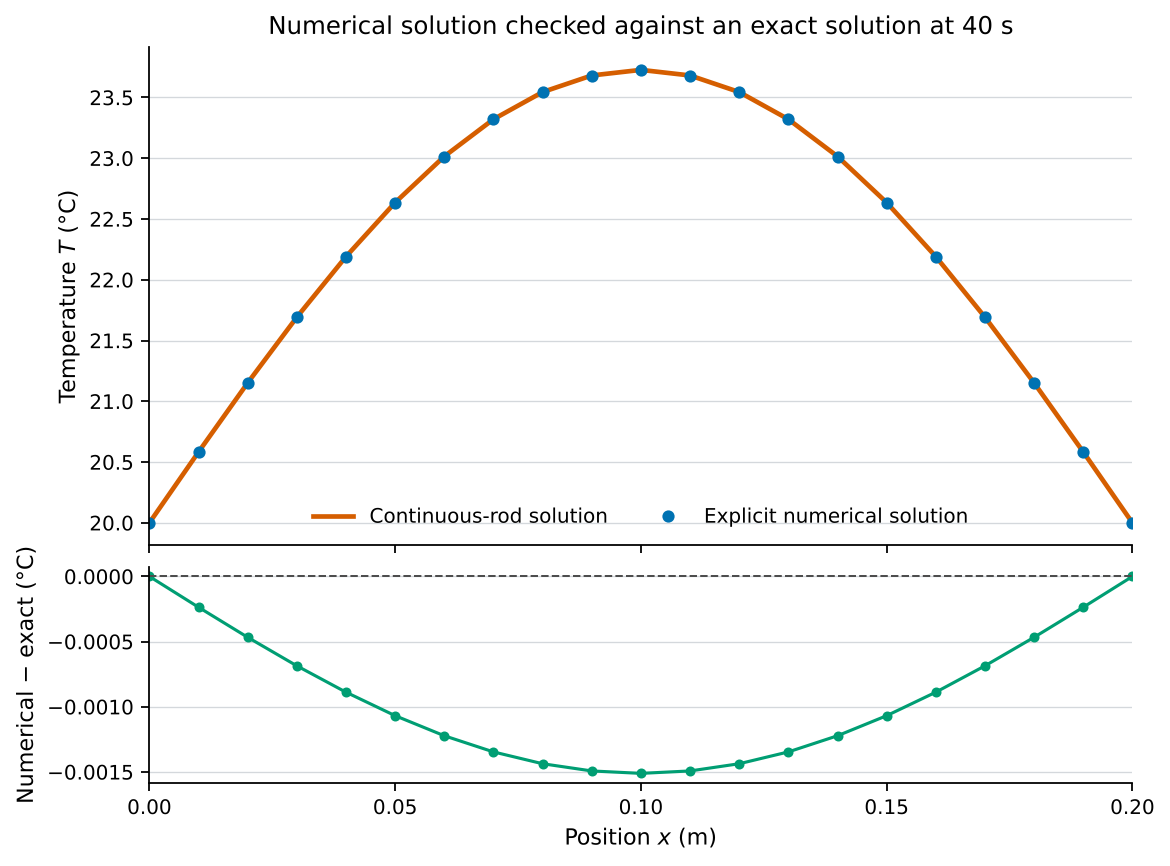

In [18]:
# Choose a physical time that corresponds to an integer 200 steps of 0.2 s.
comparison_time = 40.0
# Convert that physical time to a whole number of updates for our original dt.
comparison_steps = int(round(comparison_time / dt))
# Run the fixed-end solver with both ends held at the reference temperature.
numerical_sine = simulate_fixed(T_sine_initial, alpha, dx, dt, comparison_steps, reference_temperature, reference_temperature, [comparison_steps])[comparison_steps]
# Evaluate the independent continuous-rod formula at the same locations and time.
known_sine = exact_sine(x, comparison_time, alpha, L, reference_temperature, amplitude)
# Compare their largest absolute difference across all nodes.
sine_error = np.max(np.abs(numerical_sine - known_sine))
# Print the error in degrees Celsius, rather than declaring the plots identical.
print(f"Largest error after {comparison_time:g} s: {sine_error:.5f} °C")
# Create aligned panels so a tiny discrepancy is visible below the main profiles.
fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.3), sharex=True, gridspec_kw={"height_ratios": [2.3, 1.0]}, layout="constrained")
# Draw the independent continuous solution first so points remain visible above it.
axes[0].plot(x, known_sine, color=plot_colors[3], linewidth=2.1, label="Continuous-rod solution")
# Display computed nodal values as markers rather than a misleading second curve.
axes[0].plot(x, numerical_sine, "o", color=plot_colors[0], markersize=4.5, label="Explicit numerical solution")
# Show the physical temperature scale on the larger upper panel.
axes[0].set_ylabel("Temperature $T$ (°C)")
# State the shared time of the two independently obtained profiles.
axes[0].set_title("Numerical solution checked against an exact solution at 40 s")
# Put the two-method legend in the open area beneath the peak.
axes[0].legend(loc="lower center", ncol=2, frameon=False)
# Restrict both panels to the actual extent of the rod.
axes[0].set_xlim(0.0, L)
# Put light horizontal guides behind the observations.
axes[0].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Plot signed differences, which are small compared with the temperature excess.
axes[1].plot(x, numerical_sine - known_sine, "o-", color=plot_colors[2], markersize=3.5, linewidth=1.4)
# Mark zero difference as a reference for direction and magnitude of error.
axes[1].axhline(0.0, color=plot_colors[5], linewidth=0.9, linestyle="--")
# Name the sign convention for the lower panel without hiding the small scale.
axes[1].set_ylabel("Numerical − exact (°C)")
# Label the shared position axis in SI units.
axes[1].set_xlabel("Position $x$ (m)")
# Use the same position tick marks as the other spatial figures.
axes[1].set_xticks(np.linspace(0.0, L, 5))
# Add faint guides to read the signed residuals accurately.
axes[1].grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render the verification plot.
plt.show()

**Figure 3.** At 40 s, the computed nodes and exact sine curve nearly coincide (upper panel). The lower panel magnifies their signed differences in °C. A close visual match alone would not reveal this small numerical error.

### Optional numerical study A: change only the time step

To see the effect of $\Delta t$ without mixing in spatial error, hold the **same 21-node grid** and compare against an exact formula for that grid's discrete sine mode. For this particular spatial grid, the sine excess decays continuously in time at rate

$$\lambda_h=\frac{4\alpha}{(\Delta x)^2}\sin^2\left(\frac{\pi\Delta x}{2L}\right),\qquad
T_{\mathrm{grid}}(x,t)=20+10\sin(\pi x/L)e^{-\lambda_h t}.$$

This is a more specialized benchmark: it solves the space-discretized model **without** time-stepping error. Comparing to it isolates the effect of the time step. Students can treat the formula as provided and focus on the experiment. Each choice reaches exactly 40 s.

In [19]:
# Compute the decay rate of this grid's discrete spatial sine mode.
grid_decay_rate = 4.0 * alpha * np.sin(np.pi * dx / (2.0 * L))**2 / dx**2
# Evaluate the exact-in-time prediction for the unchanged 21-node grid.
grid_reference = reference_temperature + amplitude * np.sin(np.pi * x / L) * np.exp(-grid_decay_rate * comparison_time)
# Try progressively shorter time steps while leaving the spatial nodes unchanged.
time_steps_to_try = [0.40, 0.20, 0.10]
# Collect quantitative differences for a small comparison table.
time_errors = []
# Repeat the numerical experiment for each candidate time step.
for trial_dt in time_steps_to_try:
    # Calculate the exact integer count that reaches the shared final time.
    trial_count = int(round(comparison_time / trial_dt))
    # Compute a final profile using the chosen temporal resolution.
    trial_profile = simulate_fixed(T_sine_initial, alpha, dx, trial_dt, trial_count, reference_temperature, reference_temperature, [trial_count])[trial_count]
    # Measure the maximum error relative to the exact-in-time grid benchmark.
    trial_error = np.max(np.abs(trial_profile - grid_reference))
    # Add this single result to the table of time-step errors.
    time_errors.append(trial_error)
    # Show the ratio and error so students can connect dt to stability and accuracy.
    print(f"dt={trial_dt:.2f} s, r={alpha*trial_dt/dx**2:.2f}, time-only max error={trial_error:.5f} °C")
# Confirm that this example improves as the time step is reduced.
assert time_errors[0] > time_errors[1] > time_errors[2]

dt=0.40 s, r=0.40, time-only max error=0.01819 °C
dt=0.20 s, r=0.20, time-only max error=0.00908 °C
dt=0.10 s, r=0.10, time-only max error=0.00453 °C


### Optional numerical study B: change the grid spacing

Now use 11, 21, then 41 nodal points. Keep $r=0.2$, which means $\Delta t$ must shrink as $\Delta x^2$. The three step counts are 50, 200, and 800 for the common final time of 40 s. This time we compare with the **continuous-rod** sine formula, so the reported discrepancy includes both space and time errors. We expect a finer grid to improve this smooth example; that does not mean arbitrarily fine grids are free, because they require more nodes and many more updates.

In [20]:
# Fix the neighbor-exchange ratio to compare grids under one stability setting.
target_ratio = 0.20
# Choose three node counts whose spacings are successively halved.
grid_sizes = [11, 21, 41]
# Prepare to collect maximum errors against the continuous-rod formula.
space_errors = []
# Repeat the full sine experiment on each independently generated grid.
for trial_N in grid_sizes:
    # Recreate physical node positions for the current resolution.
    trial_x = np.linspace(0.0, L, trial_N)
    # Determine the new distance between its adjacent nodal positions.
    trial_dx = L / (trial_N - 1)
    # Choose a time step that keeps alpha*dt/dx² at the desired safe value.
    trial_dt = target_ratio * trial_dx**2 / alpha
    # Find the number of time steps required to reach 40 physical seconds.
    trial_count = int(round(comparison_time / trial_dt))
    # Make the same physical sine-shaped starting temperature on the new grid.
    trial_start = reference_temperature + amplitude * np.sin(np.pi * trial_x / L)
    # Enforce the same prescribed baseline at both grid endpoints.
    trial_start[[0, -1]] = reference_temperature
    # Run to the common final time using the current node count and time step.
    trial_result = simulate_fixed(trial_start, alpha, trial_dx, trial_dt, trial_count, reference_temperature, reference_temperature, [trial_count])[trial_count]
    # Calculate the independent continuum answer at these new node locations.
    trial_exact = exact_sine(trial_x, comparison_time, alpha, L, reference_temperature, amplitude)
    # Measure the largest temperature discrepancy on the current grid.
    trial_error = np.max(np.abs(trial_result - trial_exact))
    # Keep the error so the trend can be checked after all three runs.
    space_errors.append(trial_error)
    # Print resolution, time step, update count, and temperature error together.
    print(f"N={trial_N:2d}, dx={trial_dx:.3f} m, dt={trial_dt:.3f} s, steps={trial_count:3d}, error={trial_error:.5f} °C")
# Check that refining both space and linked time steps helps this smooth case.
assert space_errors[0] > space_errors[1] > space_errors[2]

N=11, dx=0.020 m, dt=0.800 s, steps= 50, error=0.00603 °C
N=21, dx=0.010 m, dt=0.200 s, steps=200, error=0.00151 °C


N=41, dx=0.005 m, dt=0.050 s, steps=800, error=0.00038 °C


## 6. A diagnostic: when a computer invents heat

For our explicit formula, $r>1/2$ makes the weight on the middle old value negative. Some patterns can then alternate and grow instead of flattening. We deliberately create a tiny alternating perturbation (only 0.1 °C) at the interior nodes. We compare $r=0.4$ and $r=0.6$ for **35 updates**. These runs have different physical time steps, so the plot is about numerical behavior per update, not a physical same-time comparison. The stable simulation driver correctly rejects $r=0.6$; this experiment calls the one-step rule directly for teaching purposes.

In [21]:
# Make a uniform 20 °C baseline over the original nodal grid.
alternating_start = np.full(N, reference_temperature)
# Build the integer indices of the 19 interior nodes.
interior_indices = np.arange(1, N - 1)
# Add alternating positive and negative 0.1 °C deviations only in the interior.
alternating_start[1:-1] += 0.1 * (-1.0)**interior_indices
# Display the first few entries to make the alternating pattern visible.
print("First seven perturbations (°C):", np.round(alternating_start[:7] - reference_temperature, 3))
# Verify that both fixed endpoint temperatures were left at the baseline.
assert np.allclose(alternating_start[[0, -1]], reference_temperature)

First seven perturbations (°C): [ 0.  -0.1  0.1 -0.1  0.1 -0.1  0.1]


In [22]:
# Store the largest deviation from 20 °C after each stable update.
stable_amplitudes = [np.max(np.abs(alternating_start - reference_temperature))]
# Store the corresponding deviations from a deliberately unsafe update.
unstable_amplitudes = [np.max(np.abs(alternating_start - reference_temperature))]
# Make separate copies because each run evolves independently.
stable_current = alternating_start.copy()
# Make another separate copy for the deliberately unstable run.
unstable_current = alternating_start.copy()
# Perform 35 updates for each ratio, long enough to show different behavior.
for update_number in range(35):
    # Advance the stable copy using a nonnegative middle weight.
    stable_current = fixed_step(stable_current, 0.4, reference_temperature, reference_temperature)
    # Advance the other copy with the unsafe negative middle weight.
    unstable_current = fixed_step(unstable_current, 0.6, reference_temperature, reference_temperature)
    # Record the maximum absolute deviation produced by the stable run.
    stable_amplitudes.append(np.max(np.abs(stable_current - reference_temperature)))
    # Record the maximum absolute deviation produced by the unstable run.
    unstable_amplitudes.append(np.max(np.abs(unstable_current - reference_temperature)))
# Show the contrasting final deviations with their temperature units.
print(f"After 35 updates: stable deviation={stable_amplitudes[-1]:.4g} °C; unsafe deviation={unstable_amplitudes[-1]:.4g} °C")

After 35 updates: stable deviation=0.0004804 °C; unsafe deviation=1.123e+04 °C


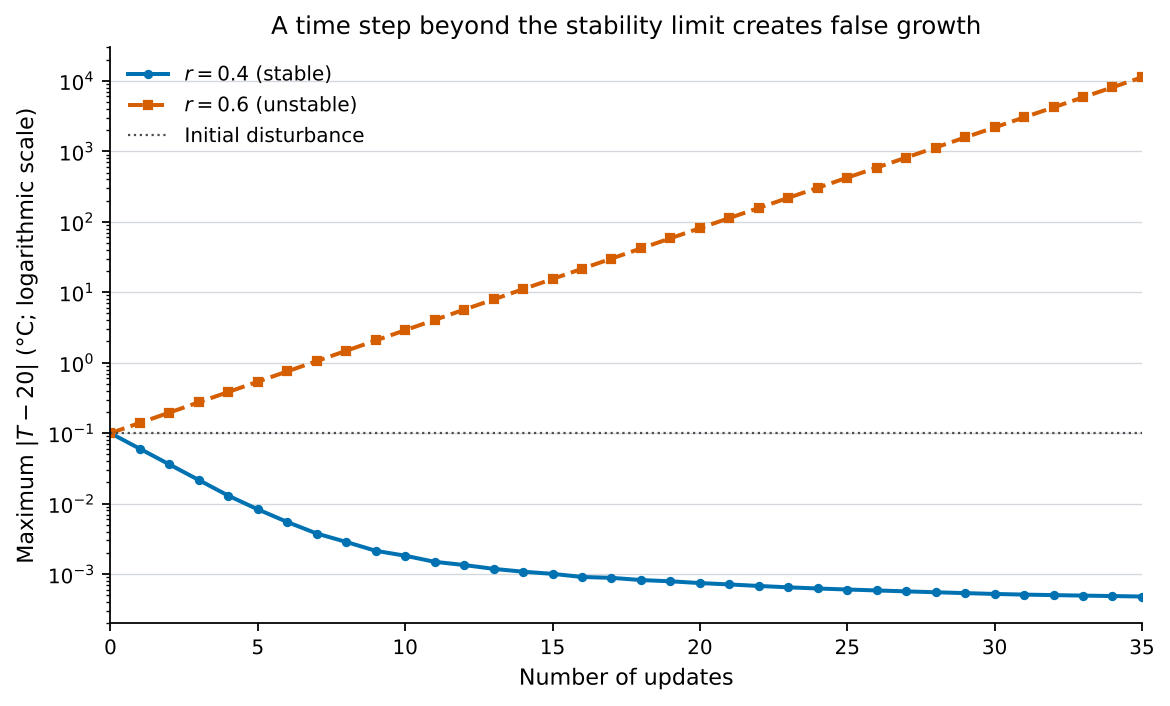

In [23]:
# Create an update-number axis from zero through 35 inclusive.
update_axis = np.arange(len(stable_amplitudes))
# Create a single panel tall enough for a wide range on a logarithmic axis.
fig, ax = plt.subplots(figsize=(7.2, 4.3), layout="constrained")
# Trace the safe ratio with blue points and a solid connecting line.
ax.semilogy(update_axis, stable_amplitudes, "o-", color=plot_colors[0], markersize=3.2, linewidth=1.8, label="$r=0.4$ (stable)")
# Trace the deliberately unsafe ratio with orange points and a dashed line.
ax.semilogy(update_axis, unstable_amplitudes, "s--", color=plot_colors[3], markersize=3.2, linewidth=1.8, label="$r=0.6$ (unstable)")
# Mark the shared initial 0.1 °C disturbance as a comparison level.
ax.axhline(0.1, color=plot_colors[5], linewidth=1.0, linestyle=":", label="Initial disturbance")
# Explain that the horizontal scale counts algorithms steps, not seconds.
ax.set_xlabel("Number of updates")
# State the absolute temperature deviation and the logarithmic scale explicitly.
ax.set_ylabel("Maximum $|T-20|$ (°C; logarithmic scale)")
# Make clear that the growth results from a numerical setting.
ax.set_title("A time step beyond the stability limit creates false growth")
# Limit the plot to the update range actually computed.
ax.set_xlim(0, 35)
# Keep the full contrast between decay and growth in view.
ax.set_ylim(2e-4, 3e4)
# Place the legend in a region free of the growing curve's late-time values.
ax.legend(loc="upper left", frameon=False)
# Use log-grid guides to show each factor-of-ten change in magnitude.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the diagnostic plot.
plt.show()
# Verify that the unstable run grew substantially in this constructed example.
assert unstable_amplitudes[-1] > 10.0 * unstable_amplitudes[0]
# Verify that the stable run did not increase its original maximum deviation.
assert stable_amplitudes[-1] <= stable_amplitudes[0]

**Figure 4.** Maximum departure from 20 °C after each update of a small alternating perturbation. The vertical scale is logarithmic: adjacent powers of ten represent a tenfold change. The $r=0.6$ curve is a deliberately invalid numerical result. The two runs use different $\Delta t$, so their horizontal axes compare update counts rather than equal physical times.

### Another programming pitfall: overwriting the old values

Suppose we update an array directly from left to right. At node 2, the left neighbor at node 1 has **already** changed. This is a different algorithm, whose result depends on traversal order. To demonstrate the bug, we use a nonuniform old profile and compare one correct update with one in-place update. The intentionally flawed loop is presented only as a diagnostic; use `fixed_step` in the actual model.

In [24]:
# Start with the two-second nonuniform profile so adjacent interiors can both change.
old_example = current.copy()
# Calculate one simultaneous-snapshot update by the intended function.
correct_example = fixed_step(old_example, r, left_temperature, right_temperature)
# Copy the old profile for the intentionally flawed in-place experiment.
in_place_example = old_example.copy()
# Move from left to right, causing later calculations to read updated left neighbors.
for i in range(1, N - 1):
    # Intentionally overwrite the array that also supplies the next node's input.
    in_place_example[i] += r * (in_place_example[i - 1] - 2.0 * in_place_example[i] + in_place_example[i + 1])
# Quantify the discrepancy that the overwrite introduced in a single step.
overwrite_difference = np.max(np.abs(in_place_example - correct_example))
# Print the nonzero discrepancy as evidence that array update order matters.
print(f"Largest one-step difference caused by in-place updating: {overwrite_difference:.6f} °C")
# Check that this chosen profile actually exposes the in-place updating error.
assert overwrite_difference > 0.0

Largest one-step difference caused by in-place updating: 0.401328 °C


## 7. A different physical experiment: insulated ends

What if neither end exchanges heat with the surroundings? Energy can still move between pieces inside the rod, but there is no heat flow across its ends. We use **20 equal cells** and store one temperature at each **cell center**: $x_i=(i+1/2)\Delta x$, with $\Delta x=L/20$. This is intentionally a different grid convention from the earlier 21-node grid, because the cell-centered arrangement makes the accounting at insulated ends especially clear.

At an interior cell, use the same neighbor rule. The first cell has only its right neighbor inside the rod: $T_0^{\mathrm{new}}=T_0^{\mathrm{old}}+r(T_1^{\mathrm{old}}-T_0^{\mathrm{old}})$. The last cell is analogous. Since each internal transfer appears once as a gain and once as a loss, **the sum and mean of all equally sized cells stay constant**. The temperature variations shrink even though the mean stays fixed. Notice the difference between *conserving the mean temperature* and *conserving the sum of squared deviations*; the latter decreases as the rod evens out.

In [25]:
# Use 20 equal cell volumes rather than 21 endpoint-inclusive nodal values.
cell_count = 20
# Compute the width of each cell so their combined length is the rod length.
cell_dx = L / cell_count
# Locate temperatures at the centers of the cells rather than at x=0 and x=L.
cell_x = (np.arange(cell_count) + 0.5) * cell_dx
# Start from a 20 °C baseline plus a smooth hot region near the middle.
insulated_initial = 20.0 + 50.0 * np.exp(-((cell_x - L / 2.0) / 0.020)**2)
# Compute the initial average temperature of the equal-sized insulated cells.
initial_mean = np.mean(insulated_initial)
# Report the cell-center locations and conserved average as a physical prediction.
print(f"First/last centers: {cell_x[0]:.3f}, {cell_x[-1]:.3f} m; initial mean = {initial_mean:.4f} °C")

First/last centers: 0.005, 0.195 m; initial mean = 28.8623 °C


In [26]:
# Define one heat-exchange update for equally sized insulated cells.
def insulated_step(old, ratio):
    # Require at least two cells to make an internal neighboring pair.
    if len(old) < 2:
        # Explain that a one-cell array cannot use the neighbor formula here.
        raise ValueError("An insulated rod needs at least two cells.")
    # Copy the old snapshot so every cell uses temperatures from the same time.
    new = old.copy()
    # Exchange heat between the first cell and its only interior neighbor.
    new[0] = old[0] + ratio * (old[1] - old[0])
    # Visit cells that have both a left and a right neighbor inside the rod.
    for i in range(1, len(old) - 1):
        # Update an interior cell with the same two-neighbor rule as before.
        new[i] = old[i] + ratio * (old[i - 1] - 2.0 * old[i] + old[i + 1])
    # Exchange heat between the last cell and its only interior neighbor.
    new[-1] = old[-1] + ratio * (old[-2] - old[-1])
    # Return the new temperature profile without changing the old input.
    return new

Keep $\Delta t=0.2$ s. Here the cell width happens to equal our old node spacing, so $r=0.2$ again. We save snapshots up to 200 s and also monitor the average and the variance over all 1000 updates. Variance is the mean squared distance from the mean; it tells us how uneven the temperatures are.

In [27]:
# Calculate the update ratio for the cell-centered grid.
cell_ratio = alpha * dt / cell_dx**2
# Select three times at which to inspect the spatial temperature profile.
insulated_keep = [0, 100, 1000]
# Start the insulated experiment from a private copy of its initial condition.
insulated_current = insulated_initial.copy()
# Preserve an independent snapshot at step zero.
insulated_snapshots = {0: insulated_current.copy()}
# Record the initial mean before any internal exchange.
insulated_means = [np.mean(insulated_current)]
# Record the initial unevenness before the hot region spreads.
insulated_variances = [np.var(insulated_current)]
# Step forward 1000 times, corresponding to 200 seconds.
for index in range(1, 1001):
    # Make one simultaneous old-to-new insulated update.
    insulated_current = insulated_step(insulated_current, cell_ratio)
    # Retain the average to test the no-external-flux prediction.
    insulated_means.append(np.mean(insulated_current))
    # Retain the variance to see temperature differences relax.
    insulated_variances.append(np.var(insulated_current))
    # Check whether this particular step was selected for a profile plot.
    if index in insulated_keep:
        # Copy the chosen profile before subsequent steps alter the current array.
        insulated_snapshots[index] = insulated_current.copy()
# Show how close the final mean is to the original mean after 1000 steps.
print(f"Mean: start={initial_mean:.8f} °C, end={insulated_means[-1]:.8f} °C")
# Check conservation of the mean to a stringent floating-point tolerance.
assert np.allclose(insulated_means, initial_mean, atol=1e-10)
# Check that the final profile is more uniform than the starting profile.
assert insulated_variances[-1] < insulated_variances[0]

Mean: start=28.86226925 °C, end=28.86226925 °C


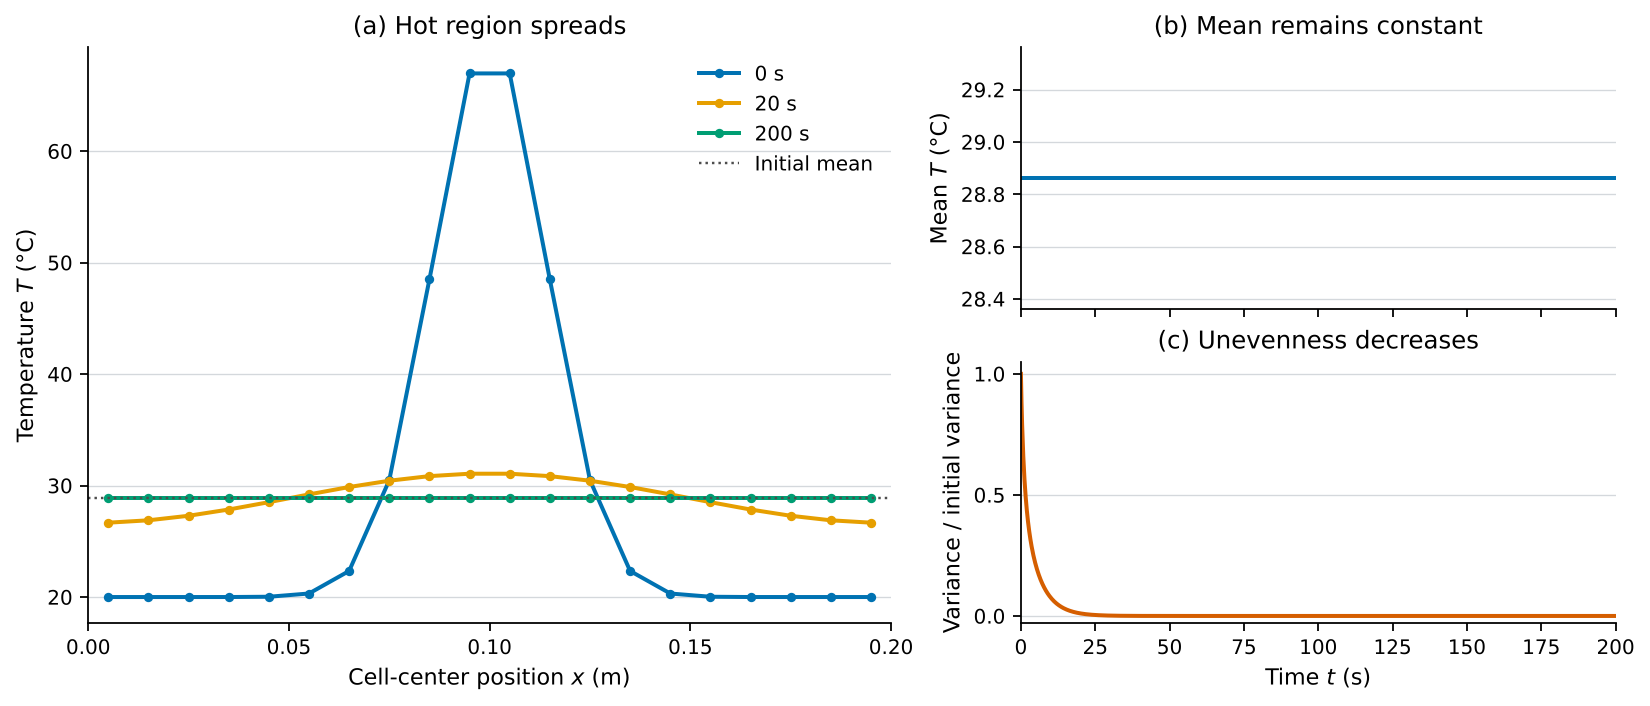

In [28]:
# Create a figure with one spatial panel and two separate temporal panels.
fig = plt.figure(figsize=(10.2, 4.3), layout="constrained")
# Give the spatial panel slightly more width than the diagnostic column.
grid = fig.add_gridspec(2, 2, width_ratios=[1.35, 1.0])
# Make a spatial panel that occupies the full left-hand column.
ax_profile = fig.add_subplot(grid[:, 0])
# Make a separate upper-right axis for the mean temperature.
ax_mean = fig.add_subplot(grid[0, 1])
# Make a lower-right axis for variance, sharing elapsed time with the mean.
ax_variance = fig.add_subplot(grid[1, 1], sharex=ax_mean)
# Draw each selected temperature profile against physical cell-center positions.
for position, index in enumerate(insulated_keep):
    # Connect equal-volume cell values while retaining small visible markers.
    ax_profile.plot(cell_x, insulated_snapshots[index], "o-", color=plot_colors[position], markersize=3.2, linewidth=1.8, label=f"{index * dt:g} s")
# Show the conserved average as a dotted reference through the spatial profiles.
ax_profile.axhline(initial_mean, color=plot_colors[5], linestyle=":", linewidth=1.1, label="Initial mean")
# Label physical cell-center position and its SI unit.
ax_profile.set_xlabel("Cell-center position $x$ (m)")
# Label the temperatures and their unit.
ax_profile.set_ylabel("Temperature $T$ (°C)")
# Label the first panel with a compact description.
ax_profile.set_title("(a) Hot region spreads")
# Keep the axis within the physical length of the rod.
ax_profile.set_xlim(0.0, L)
# Match the other spatial figures' position ticks.
ax_profile.set_xticks(np.linspace(0.0, L, 5))
# Identify the three times and the conserved mean.
ax_profile.legend(loc="upper right", frameon=False)
# Add light horizontal guides for temperature comparison.
ax_profile.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Construct elapsed times for all 1001 mean and variance observations.
insulated_times = np.arange(1001) * dt
# Plot the measured mean on its own Celsius axis instead of mixing units.
ax_mean.plot(insulated_times, insulated_means, color=plot_colors[0], linewidth=1.8)
# Label the second panel as a conservation check.
ax_mean.set_title("(b) Mean remains constant")
# Label the mean temperature with its Celsius unit.
ax_mean.set_ylabel("Mean $T$ (°C)")
# Use a one-degree window so floating-point roundoff cannot look like heat flow.
ax_mean.set_ylim(initial_mean - 0.5, initial_mean + 0.5)
# Keep the upper time range equal to the modeled 200 seconds.
ax_mean.set_xlim(0.0, 200.0)
# Show light horizontal guides behind the mean-temperature line.
ax_mean.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Hide upper-panel time labels because the shared lower axis labels that coordinate.
ax_mean.tick_params(labelbottom=False)
# Divide variance by its initial value to show a dimensionless relaxation curve.
relative_variance = np.array(insulated_variances) / insulated_variances[0]
# Plot unevenness on its own axis without a second y scale on the mean panel.
ax_variance.plot(insulated_times, relative_variance, color=plot_colors[3], linewidth=1.8)
# Describe the third panel's physical trend.
ax_variance.set_title("(c) Unevenness decreases")
# Name the dimensionless normalized quantity on the lower vertical axis.
ax_variance.set_ylabel("Variance / initial variance")
# Label the shared physical time on the bottom horizontal axis.
ax_variance.set_xlabel("Time $t$ (s)")
# Show the complete range from an initial variance fraction of one to zero.
ax_variance.set_ylim(-0.03, 1.05)
# Mark clear zero, half, and initial fractions of unevenness.
ax_variance.set_yticks([0.0, 0.5, 1.0])
# Draw subtle guides without obscuring the fast initial decay.
ax_variance.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Render all three axes with their titles and labels separated by constrained layout.
plt.show()

**Figure 5.** Insulated equal-volume cells, initially warmer near the center: (a) spatial profiles at 0, 20, and 200 s; (b) constant mean temperature; (c) variance divided by its value at time zero. The separate time panels avoid confusing °C with a dimensionless variance fraction.

## 8. Change a material property, keeping the same geometry

Thermal diffusivity controls the time scale. In the single-sine comparison, the extra midpoint temperature is $10\exp[-\alpha(\pi/L)^2t]$. At the same 40 s, doubling $\alpha$ gives more time for temperature differences to fade *in the dimensionless sense*. For a full design, $k$, $\rho$, and $c_p$ should be chosen from measured data for the actual material and temperature range. This sensitivity experiment changes only a parameter in our simplified model.

α=5.0e-05 m²/s gives midpoint 26.105 °C at 40 s
α=1.0e-04 m²/s gives midpoint 23.727 °C at 40 s
α=2.0e-04 m²/s gives midpoint 21.389 °C at 40 s


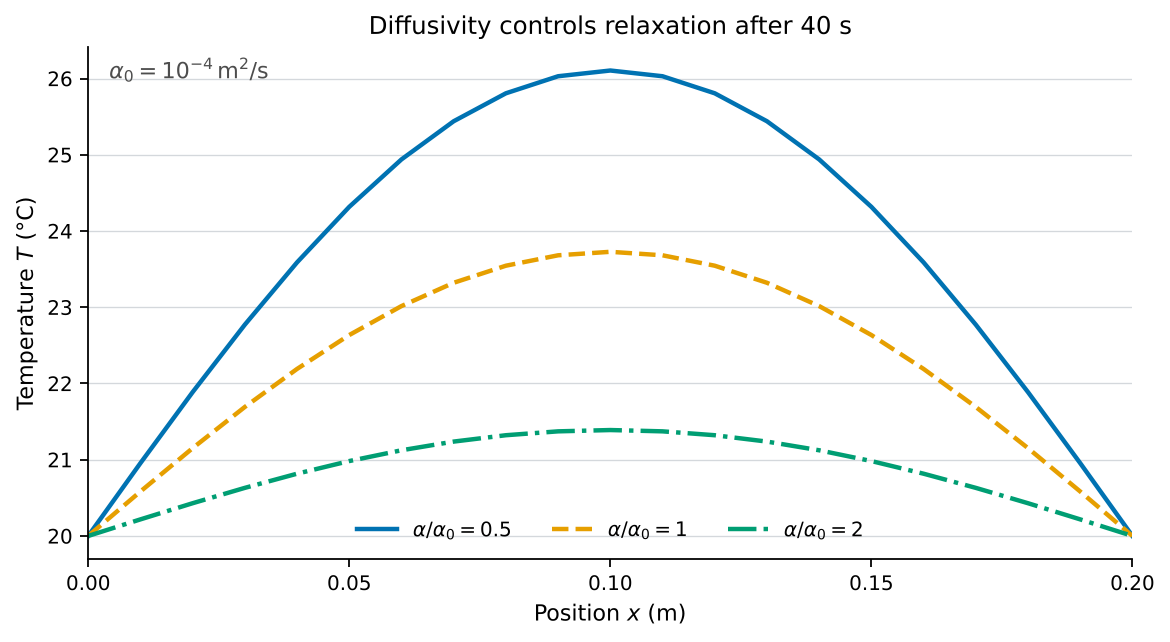

In [29]:
# Choose three thermal diffusivities around the illustrative base value.
diffusivities = [alpha / 2.0, alpha, 2.0 * alpha]
# Create a single-panel figure with the same width as the other spatial profiles.
fig, ax = plt.subplots(figsize=(7.2, 3.9), layout="constrained")
# Use a second visual cue for each curve in addition to its color.
sensitivity_patterns = ["-", "--", "-."]
# Evaluate the independent sine prediction for each illustrative parameter.
for position, trial_alpha in enumerate(diffusivities):
    # Calculate the spatial profile with the selected diffusivity at 40 seconds.
    trial_curve = exact_sine(x, comparison_time, trial_alpha, L)
    # Plot the profile with color, line pattern, and its ratio to the base diffusivity.
    ax.plot(x, trial_curve, color=plot_colors[position], linestyle=sensitivity_patterns[position], linewidth=2.0, label=fr"$\alpha/\alpha_0={trial_alpha/alpha:g}$")
    # Report the midpoint so the speed-of-equalization comparison is numerical.
    print(f"α={trial_alpha:.1e} m²/s gives midpoint {trial_curve[N//2]:.3f} °C at 40 s")
# Label the physical position consistently with the earlier figures.
ax.set_xlabel("Position $x$ (m)")
# Label observed temperature and its Celsius unit.
ax.set_ylabel("Temperature $T$ (°C)")
# State the fixed comparison time and the parameter's influence.
ax.set_title("Diffusivity controls relaxation after 40 s")
# Match the full rod extent and consistent x tick positions.
ax.set_xlim(0.0, L)
# Add evenly spaced position ticks across the 20 cm rod.
ax.set_xticks(np.linspace(0.0, L, 5))
# Clarify the baseline diffusivity that appears as alpha subscript zero in the legend.
ax.text(0.02, 0.98, r"$\alpha_0=10^{-4}\,\mathrm{m^2/s}$", transform=ax.transAxes, ha="left", va="top", color=plot_colors[5])
# Place the compact legend in space below the peak without covering any curves.
ax.legend(loc="lower center", ncol=3, frameon=False)
# Show light horizontal guides to compare the three midpoint heights.
ax.grid(axis="y", color="#D4D8DC", linewidth=0.6)
# Display the sensitivity comparison.
plt.show()

**Figure 6.** Exact sine profiles at the same time for half, equal, and twice the example diffusivity $\alpha_0=10^{-4}\ \mathrm{m^2/s}$. A larger diffusivity yields a smaller remaining temperature excess at the midpoint. The initial condition and end temperatures are identical in all three cases.

### Optional extension: the direction of heat flow

The steady fixed-end profile fell by 80 °C over $0.20$ m, so its slope is $-400\ \mathrm{K/m}$. **Fourier's law** says the heat flux through a cross section is $q=-k\,dT/dx$, in $\mathrm{W/m^2}$. Positive $q$ means energy flows toward increasing $x$, from the left heater toward the right. The temperature-controlled devices supply and remove energy, so the fixed-end rod's total stored energy need not be constant. We use an *analytic steady slope* here, not a one-sided numerical boundary estimate.

In [30]:
# Compute the exact slope of the straight-line steady temperature profile.
steady_slope = (right_temperature - left_temperature) / L
# Apply Fourier's law to obtain the heat flux through the steady rod.
steady_flux = -k * steady_slope
# Print both the negative slope and positive left-to-right flux with units.
print(f"Steady slope = {steady_slope:.1f} K/m; heat flux = {steady_flux:,.0f} W/m² toward +x")
# Check the physical direction implied by a hot-left, cool-right rod.
assert steady_slope < 0.0 and steady_flux > 0.0

Steady slope = -400.0 K/m; heat flux = 108,000 W/m² toward +x


## 9. Guided exercise: when does the middle reach 55 °C?

Return to the original experiment with the left end at 100 °C and the right at 20 °C. The middle begins at 20 °C and approaches its 60 °C steady value. Use the safe one-step function and stop at the **first** step at which the midpoint is at least 55 °C. Count steps from zero, then multiply by $\Delta t$ to report a time. Try writing your own loop before running the worked solution below. Because time is sampled in discrete steps, the reported time has resolution $0.2$ s, not infinitely precise timing.

In [31]:
# Set the target temperature for the midpoint of the original fixed-end rod.
midpoint_target = 55.0
# Reuse a new copy of the original condition with its hot and cool boundary ends.
exercise_current = T_initial.copy()
# Start the elapsed-update counter at the initial condition, which is step zero.
first_reaching_step = None
# Search for a crossing within the 2000 steps already studied above.
for index in range(1, 2001):
    # Advance once while keeping all old neighbor temperatures separate.
    exercise_current = fixed_step(exercise_current, r, left_temperature, right_temperature)
    # Detect the first update at which the middle reaches the requested value.
    if exercise_current[N // 2] >= midpoint_target:
        # Store the first successful step index for later conversion to seconds.
        first_reaching_step = index
        # End the loop immediately so this remains the first crossing.
        break
# Confirm that the target was reached inside the chosen simulation period.
assert first_reaching_step is not None
# Convert step count to elapsed physical time.
first_reaching_time = first_reaching_step * dt
# Report the observed midpoint and the sampling-limited crossing time.
print(f"The midpoint first reaches {midpoint_target:.1f} °C at step {first_reaching_step}, t={first_reaching_time:.1f} s; T={exercise_current[N//2]:.3f} °C")
# Check the result against the already known steady temperature of 60 °C.
assert midpoint_target < T_steady[N // 2]

The midpoint first reaches 55.0 °C at step 470, t=94.0 s; T=55.007 °C


## What to take away

1. **Physics:** an uneven temperature profile drives internal energy exchange. Conductivity sets the transfer strength, while density and heat capacity set how hard it is to change temperature. Their ratio is the thermal diffusivity.
2. **Programming:** an array represents a rod; indices identify neighbors; a function performs one complete old-to-new update; a loop advances time; plots and assertions test predictions.
3. **Numerical judgment:** for this one-dimensional explicit update, use $0<\alpha\Delta t/\Delta x^2\le1/2$. Compare with a known steady state and an independent time-dependent solution. Refine the grid when accuracy matters.
4. **Boundaries:** held-temperature ends can exchange energy with external devices; insulated ends cannot, and the equal-cell average remains constant. Boundary choices change the engineering question.

**Further exercises:** (a) predict what happens if the heater is on the right instead; (b) rerun the safe fixed-end simulation with $N=41$ and compute a safe $\Delta t$ first; (c) replace the insulated hot region with a cool region and check that the mean still stays fixed. For a challenge, store the midpoint at every step and plot its approach to 60 °C.

**Assumptions and limits:** constant material properties, a thin uniform rod, no side losses, no phase changes, and idealized end conditions. The explicit formula is educational and its step size can be costly for very fine grids. If using measured material values, verify units and suitability for the actual conditions.

**Optional primary-source reading:** [MIT OpenCourseWare, *The 1-D Heat Equation*](https://www.ocw.mit.edu/courses/18-303-linear-partial-differential-equations-fall-2006/d11b374a85c3fde55ec971fe587f8a50_heateqni.pdf) derives the energy balance and discusses boundary conditions; [MIT OpenCourseWare, *The Heat Equation and Convection-Diffusion*](https://ocw.mit.edu/courses/18-086-mathematical-methods-for-engineers-ii-spring-2006/resources/am54/) develops the explicit difference scheme and its stability condition. These calculus-based notes go beyond the required first-year programming route.